# 06 · Validação robusta / Robust validation

O notebook 05 usa **uma** divisão treino/teste, cujo resultado varia muito com a semente. Aqui:

1. **Vazamento:** ~41% das linhas compartilham o perfil de personalidade com outra linha. Comparamos
   validação cruzada **ingênua** vs **agrupada** por `profile_id` para medir o quanto isso infla as métricas;
2. **Validação cruzada repetida e aninhada:** 5 folds × 3 repetições, agrupados e estratificados.
   Os hiperparâmetros (penalizer do Cox, folhas/features da RSF) são ajustados **dentro** de cada fold de treino;
3. **Teste estatístico** da diferença entre modelos (t-test corrigido de Nadeau & Bengio);
4. **Calibração** do risco previsto de saída em 12 e 24 meses, usando predições *out-of-fold*.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))  # works even without `pip install -e .`
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from turnover_survival import config, data, nonparametric, models, evaluation

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
T, E = config.DURATION_COL, config.EVENT_COL

df = data.load_clean()
print(f"{len(df)} employees | {df[E].sum()} left | {1 - df[E].mean():.1%} censored")

1116 employees | 560 left | 49.8% censored


In [2]:
X = data.make_design_matrix(df)
sizes = X.groupby(config.GROUP_COL).size()
print(f"{sizes.size} profiles | {sizes[sizes > 1].sum()} rows ({sizes[sizes > 1].sum() / len(X):.0%}) in repeated profiles")
sizes.value_counts().sort_index().rename_axis("rows per profile").to_frame("profiles")

848 profiles | 462 rows (41%) in repeated profiles


,profiles
rows per profile,
1,654
2,135
3,49
4,5
5,5


## 1 · Vazamento: CV ingênua vs agrupada / Leakage: naive vs grouped CV
Hiperparâmetros fixos nesta etapa, para isolar o efeito da divisão.

In [3]:
fixed = {
    "Cox PH": lambda d: models.fit_cox(d, penalizer=0.01, robust=False),
    "Random Survival Forest": lambda d: models.fit_rsf(d, n_estimators=200),
}
leak = []
for grouped in (False, True):
    s, _ = evaluation.cross_validate(X, fixed, n_splits=5, n_repeats=3, grouped=grouped, verbose=False)
    leak.append(s.assign(split="grouped" if grouped else "naive"))
leak = pd.concat(leak)
leak_tab = leak.pivot_table(index="model", columns="split", values=["c_index", "integrated_brier"], aggfunc="mean")
for m in ["c_index", "integrated_brier"]:
    leak_tab[(m, "naive − grouped")] = leak_tab[(m, "naive")] - leak_tab[(m, "grouped")]
leak_tab

c_index       integrated_brier               c_index  \
split                  grouped naive          grouped naive naive − grouped   
model                                                                         
Cox PH                   0.612 0.615            0.195 0.193           0.003   
Random Survival Forest   0.623 0.637            0.191 0.188           0.014   

                       integrated_brier  
split                   naive − grouped  
model                                    
Cox PH                           -0.002  
Random Survival Forest           -0.004

**Leitura:** se a CV ingênua dá C-index maior / IBS menor que a agrupada, o modelo está se
beneficiando de ver a "mesma pessoa" no treino. Modelos flexíveis (RSF) tendem a sofrer mais.
Daqui em diante, **só CV agrupada**.

## 2 · CV repetida e aninhada / Nested repeated grouped CV

In [4]:
fitters = {
    "Cox PH (tuned)": lambda d: models.fit_cox_tuned(d, k=3),
    "Weibull AFT": lambda d: models.fit_aft(d, "Weibull"),
    "LogNormal AFT": lambda d: models.fit_aft(d, "LogNormal"),
    "Random Survival Forest (tuned)": lambda d: models.fit_rsf_tuned(d, k=3),
}
scores, oof = evaluation.cross_validate(X, fitters, n_splits=5, n_repeats=3, horizons=(12, 24))
scores.to_csv(config.DATA_PROCESSED / "cv_scores.csv", index=False)
evaluation.summarize_cv(scores)

repeat 1/3 · fold 1/5 done


repeat 1/3 · fold 2/5 done


repeat 1/3 · fold 3/5 done


repeat 1/3 · fold 4/5 done


repeat 1/3 · fold 5/5 done


repeat 2/3 · fold 1/5 done


... (6 outputs left out)

repeat 3/3 · fold 3/5 done


repeat 3/3 · fold 4/5 done


repeat 3/3 · fold 5/5 done


c_index                   mean_td_auc        \
                                  mean   std  p2.5 p97.5        mean   std   
model                                                                        
Random Survival Forest (tuned)   0.627 0.027 0.581 0.664       0.663 0.035   
Weibull AFT                      0.612 0.021 0.578 0.643       0.641 0.023   
Cox PH (tuned)                   0.610 0.021 0.573 0.642       0.639 0.025   
LogNormal AFT                    0.608 0.021 0.574 0.647       0.639 0.026   

                                           integrated_brier                    \
                                p2.5 p97.5             mean   std  p2.5 p97.5   
model                                                                           
Random Survival Forest (tuned) 0.598 0.712            0.190 0.012 0.167 0.207   
Weibull AFT                    0.598 0.676            0.195 0.014 0.169 0.218   
Cox PH (tuned)                 0.592 0.674            0.194 0.012 0.172 0.214   
LogNormal AFT                  0.594 0.683            0.196 0.014 0.171 0.220   

                                            
                               km_baseline  
model                                       
Random Survival Forest (tuned)       0.206  
Weibull AFT                          0.206  
Cox PH (tuned)                       0.206  
LogNormal AFT                        0.206

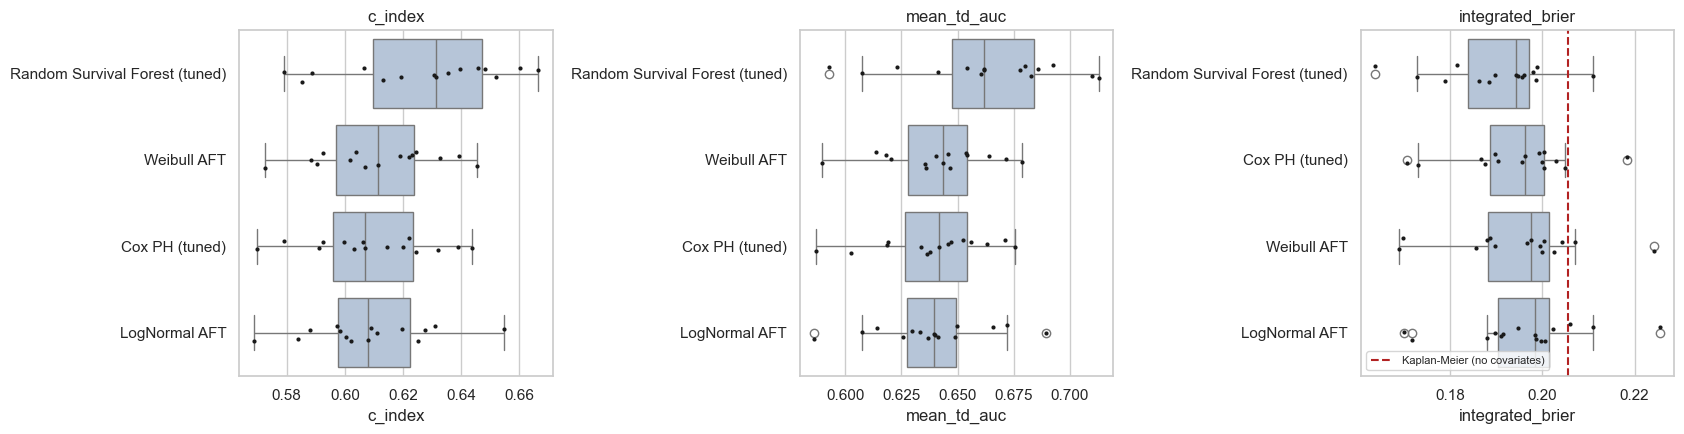

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, m in zip(axes, ["c_index", "mean_td_auc", "integrated_brier"]):
    order = scores.groupby("model")[m].mean().sort_values(ascending=(m == "integrated_brier")).index
    sns.boxplot(data=scores, y="model", x=m, order=order, ax=ax, color="lightsteelblue")
    sns.stripplot(data=scores, y="model", x=m, order=order, ax=ax, color="k", size=3)
    ax.set(ylabel="", title=m)
    if m == "integrated_brier":
        ax.axvline(scores["km_ibs"].mean(), ls="--", c="firebrick", label="Kaplan-Meier (no covariates)")
        ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "06_cv_scores.png", dpi=120, bbox_inches="tight")

Cada ponto é um fold de teste (15 no total). A dispersão mostra o quanto uma única divisão pode enganar.

## 3 · A diferença entre modelos é real? / Is the difference real?

In [6]:
best = scores.groupby("model")["c_index"].mean().idxmax()
tests = [
    evaluation.corrected_paired_ttest(scores, best, other, metric)
    for other in fitters if other != best
    for metric in ["c_index", "integrated_brier"]
]
pd.DataFrame(tests)

,comparison,metric,mean_diff,ci95_low,ci95_high,share_folds_a_better,t,p_value
0,Random Survival Forest (tuned) − Cox PH (tuned),c_index,0.017,-0.004,0.038,0.867,1.743,0.103
1,Random Survival Forest (tuned) − Cox PH (tuned),integrated_brier,-0.004,-0.009,-0.000,0.933,-2.164,0.048
2,Random Survival Forest (tuned) − Weibull AFT,c_index,0.015,-0.007,0.038,0.800,1.438,0.173
3,Random Survival Forest (tuned) − Weibull AFT,integrated_brier,-0.005,-0.011,0.001,0.867,-1.751,0.102
4,Random Survival Forest (tuned) − LogNormal AFT,c_index,0.018,-0.010,0.047,0.733,1.379,0.189
5,Random Survival Forest (tuned) − LogNormal AFT,integrated_brier,-0.006,-0.013,0.001,0.733,-1.745,0.103


- `mean_diff` > 0 no C-index (ou < 0 no IBS) favorece o primeiro modelo;
- se o **IC 95% cruza zero** (p > 0,05), os dados não sustentam que um modelo seja melhor que o outro.
  Nesse caso vale preferir o modelo **mais interpretável** (Cox/AFT).

## 4 · Calibração / Calibration

,12 months,24 months
,mean_abs_calibration_error,mean_abs_calibration_error
model,,
Cox PH (tuned),0.023,0.018
Random Survival Forest (tuned),0.024,0.032
Weibull AFT,0.040,0.061
LogNormal AFT,0.049,0.051


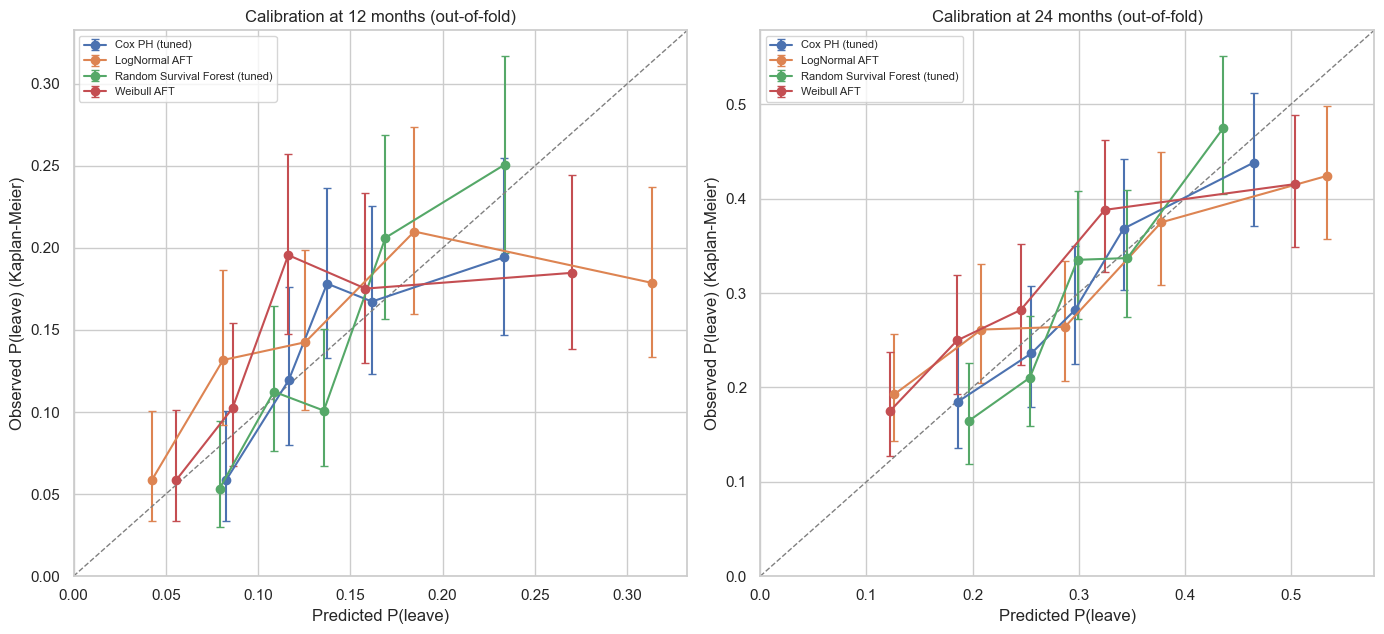

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
cal = {}
for ax, h in zip(axes, [12, 24]):
    cal[h] = evaluation.calibration_table(oof, X, horizon=h, n_bins=5)
    evaluation.plot_calibration(cal[h], horizon=h, ax=ax)
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "06_calibration.png", dpi=120, bbox_inches="tight")

pd.concat({f"{h} months": evaluation.calibration_summary(t) for h, t in cal.items()}, axis=1)

**Leitura:** cada ponto é um quintil de risco previsto. Sobre a diagonal = bem calibrado.
Pontos **acima** da diagonal → o modelo **subestima** o risco de saída nesse grupo; abaixo → superestima.
Para uso pelo RH (ex.: "30% de chance de sair em 12 meses"), a calibração importa tanto quanto o C-index.

### Conclusões / Takeaways
> _Preencha após rodar com os dados reais. / Fill in after running on the real data._